# 9. Главное в цифрах: топ-5 и где профилактика помогла

Краткая сводка по `OSHA_db` (105 996 тяжёлых травм, январь 2015 – ноябрь 2025) для презентации и итоговой части работы. Подробности — в ноутбуках 01–08.

1. Топ-5 частей тела, источников травмы, причин (типов происшествий) и отраслей: круговая диаграмма (топ-5 + «остальные») и столбчатая диаграмма с числом случаев. Вторая версия каждой круговой диаграммы — только топ-5 без «остальных»: какую долю внутри пятёрки занимает каждый её участник.
2. Какие отрасли с 2015 года стали травмироваться реже, а какие чаще: где профилактика сработала, а где ещё нужна.

Одинаковые названия под разными кодами OIICS объединены, как в разделах 1–8.

In [1]:
import os
if not os.path.isdir("src"):  # ноутбук запущен из notebooks/, а не из Analysis/
    os.chdir("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from scipy import stats

from src.db import query
from src.viz import set_style, tr, finish, barh_ranked, wrap, LANGS, TABLES_DIR, MAIN, ACCENT, SERIES
from src.stats import num, cramers_v, share_ci, rank_by_title
from src.labels import (norm_title, body_part_ru, source_ru, event_ru, sector_code, SECTORS,
                        naics_ru, NAICS_LEGACY_EN)

set_style()
TABLES_DIR.mkdir(exist_ok=True)

In [2]:
cases = query("""
    SELECT i.id,
           i.event_date,
           i.part_of_body_code, b.title AS body_part,
           i.source_code,       s.title AS source,
           i.event_code,        e.title AS event,
           i.naics_code,
           i.severity_code
    FROM injuries i
    JOIN body_part_lookup b ON b.code = i.part_of_body_code
    JOIN source_lookup    s ON s.code = i.source_code
    JOIN event_lookup     e ON e.code = i.event_code
""")
cases["event_date"] = pd.to_datetime(cases["event_date"])
cases["year"] = cases["event_date"].dt.year
cases["sector"] = cases["naics_code"].map(sector_code)
cases["subsector"] = cases["naics_code"].str[:3]
naics = query("SELECT code, title FROM naics_lookup").set_index("code")["title"]
N = len(cases)
print(f"Случаев: {num(N)}")

Случаев: 105 996


### Укрупнение

Для сводки близкие коды объединены в смысловые группы, иначе одна и та же зона риска занимает несколько мест топа (например, три кода пальцев рук или падения с разной высоты). Правила — по ключевым словам в названии, в порядке списка; всё, что не попало в группу, остаётся под своим (объединённым) названием.

In [3]:
import re

# (ru, en, шаблон по названию, раздел типа происшествия или None)
GROUPS = {
    "body_part": [
        ("Пальцы рук", "Fingers", r"finger|thumb", None),
        ("Тазобедренная область", "Hips", r"^hip", None),
    ],
    "source": [
        ("Полы и поверхности", "Floors and walking surfaces", r"floor|walkway|ground surface|constructed surface|parking lot", None),
        ("Погрузчики, паллетные тележки", "Forklifts, pallet jacks", r"forklift|pallet jack", None),
        ("Лестницы, стремянки", "Ladders", r"ladder", None),
        ("Жара окружающей среды", "Environmental heat", r"^heat.environmental", None),
        ("Конвейеры", "Conveyors", r"conveyor", None),
    ],
    "event": [
        ("Падение с высоты", "Fall to lower level", r"fall.*to lower level|fall from|fall through", None),
        ("Затягивание в работающее оборудование", "Caught in running equipment",
         r"caught in running|entangled in running|caught in or compressed by equipment", None),
        ("Падение на одном уровне (поскользнулся, споткнулся)", "Fall on same level (slip, trip)",
         r"fall on same level|slip|trip", "4"),
        ("Удар падающим или отлетевшим предметом", "Struck by falling or flying object",
         r"struck by (falling|object falling|dislodged|flying|discharged)", None),
        ("Удар движущейся частью машины", "Struck by moving machine part",
         r"struck against moving part|struck by running powered|struck by swinging part", None),
        ("Сдавливание предметами, оборудованием", "Compressed or pinched by objects",
         r"compressed or pinched|crushed|caught between", "6"),
        ("Наезд транспорта на пешехода", "Pedestrian struck by vehicle", r"pedestrian struck", None),
        ("Жара окружающей среды", "Environmental heat", r"environmental heat", None),
    ],
}
RU = {"body_part": body_part_ru, "source": source_ru, "event": event_ru}

def group_titles(col):
    # группа (ru, en) для каждого случая; вне групп — объединённое название и его перевод
    div = cases["event_code"].astype(str).str[0]
    names = rank_by_title(cases[col], cases[col.replace("body_part", "part_of_body") + "_code"])["title"]
    out_ru, out_en = [], []
    for title, d in zip(cases[col], div):
        for ru, en, pat, need_div in GROUPS[col]:
            if re.search(pat, title, re.I) and not title.lower().startswith("fans") and need_div in (None, d):
                out_ru.append(ru); out_en.append(en)
                break
        else:
            t = names[norm_title(title)]
            out_ru.append(RU[col](t)); out_en.append(t)
    return pd.Series(out_ru, index=cases.index), pd.Series(out_en, index=cases.index)

def top5(col, exclude=("Nonclassifiable",)):
    ru, en = group_titles(col)
    t = (pd.DataFrame({"title_ru": ru, "title": en}).value_counts().rename("cases").reset_index())
    t = t[~t["title"].isin(exclude)].head(5).reset_index(drop=True)
    t["title"] = t["title"].map(lambda x: x.capitalize() if x.isupper() else x)
    t["pct"] = 100 * t["cases"] / N
    t.index += 1
    return t

In [4]:
OTHER = "#c8c8c8"

def pie_bar(top, labels, title, xlabel, name, lang, note=None):
    # слева — кольцевая диаграмма (топ-5 + остальные), справа — столбцы топ-5 теми же цветами
    colors = SERIES[:len(top)]
    rest = N - top["cases"].sum()
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1.5]})
    _, _, autotexts = ax1.pie(
        list(top["cases"]) + [rest], colors=colors + [OTHER], startangle=90, counterclock=False,
        autopct=lambda p: f"{p:.1f}%", pctdistance=0.77,
        wedgeprops={"edgecolor": "white", "linewidth": 2, "width": 0.46}, textprops={"fontsize": 10})
    for t in autotexts[:-1]:
        t.set_color("white")
        t.set_fontweight("bold")
    autotexts[-1].set_text("")
    ax1.text(0, 0, tr("остальные\n", "other\n", lang) + f"{100 * rest / N:.0f}%",
             ha="center", va="center", fontsize=11, color="#555555")
    ax1.set_aspect("equal")

    barh_ranked(ax2, labels, top["cases"], color=colors, width=38,
                notes=[f"{num(c)} ({p:.1f}%)" for c, p in zip(top["cases"], top["pct"])])
    ax2.set_xlabel(xlabel)
    if note:
        ax2.text(0, -0.13, note, transform=ax2.transAxes, fontsize=9, color="#555555", va="top")
    fig.suptitle(title, fontweight="bold", fontsize=14)
    fig.tight_layout()
    finish(fig, name, lang)


def pie_top5(top, labels, title, name, lang, note=None):
    # вторая версия: кольцо только из топ-5 (без «остальных») — доля каждого внутри топ-5
    colors = SERIES[:len(top)]
    total = top["cases"].sum()
    fig, ax = plt.subplots(figsize=(11, 6))
    wedges, _, autotexts = ax.pie(
        top["cases"], colors=colors, startangle=90, counterclock=False,
        autopct=lambda p: f"{p:.1f}%", pctdistance=0.77,
        wedgeprops={"edgecolor": "white", "linewidth": 2, "width": 0.46}, textprops={"fontsize": 10})
    for t in autotexts:
        t.set_color("white")
        t.set_fontweight("bold")
    ax.text(0, 0, tr("топ-5 =\n", "top 5 =\n", lang) + f"{100 * total / N:.0f}%\n"
            + tr("всех случаев", "of all cases", lang),
            ha="center", va="center", fontsize=11, color="#555555")
    ax.set_aspect("equal")
    ax.legend(wedges, [f"{wrap(l, 38)}\n{num(c)} ({100 * c / total:.1f}%)" for l, c in zip(labels, top["cases"])],
              loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=10, frameon=False, labelspacing=1.1)
    ax.set_title(title, fontweight="bold", fontsize=14)
    foot = tr("Проценты — доля внутри топ-5 (сумма = 100%), а не от всех случаев",
              "Percentages are shares within the top 5 (sum = 100%), not of all cases", lang)
    ax.text(0, -0.06, foot + (f"\n{note}" if note else ""), transform=ax.transAxes,
            fontsize=9, color="#555555", va="top")
    finish(fig, name, lang)


## 9.1. Топ-5 пострадавших частей тела

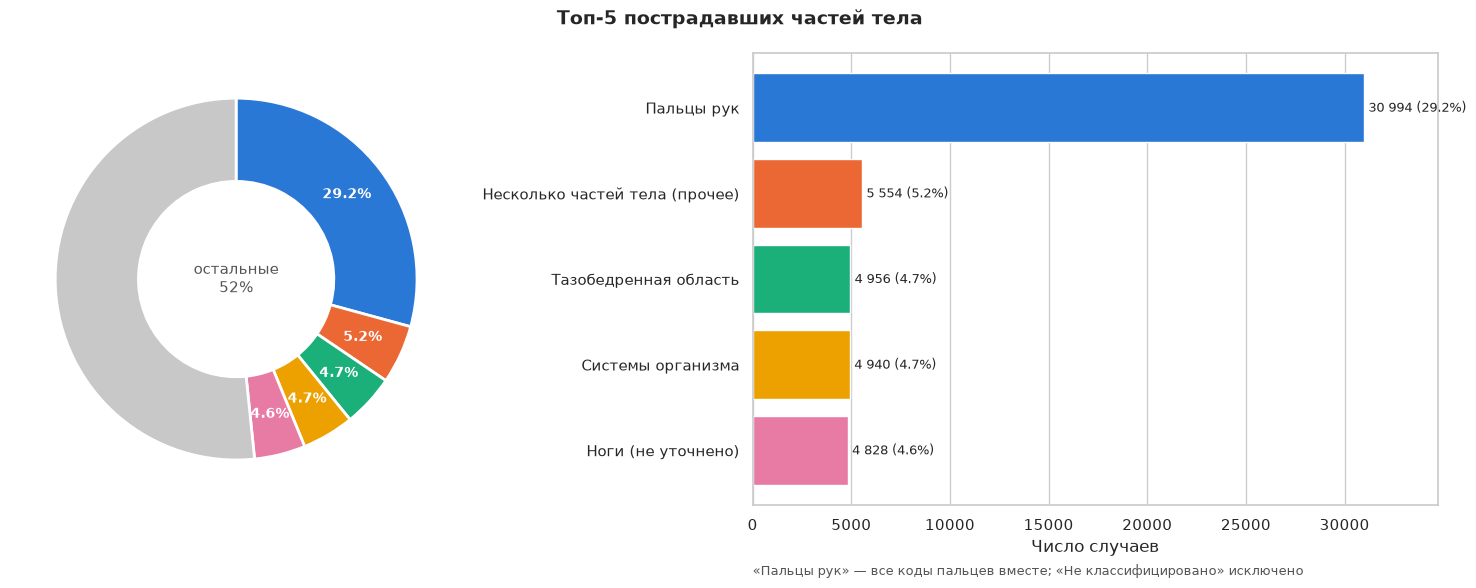

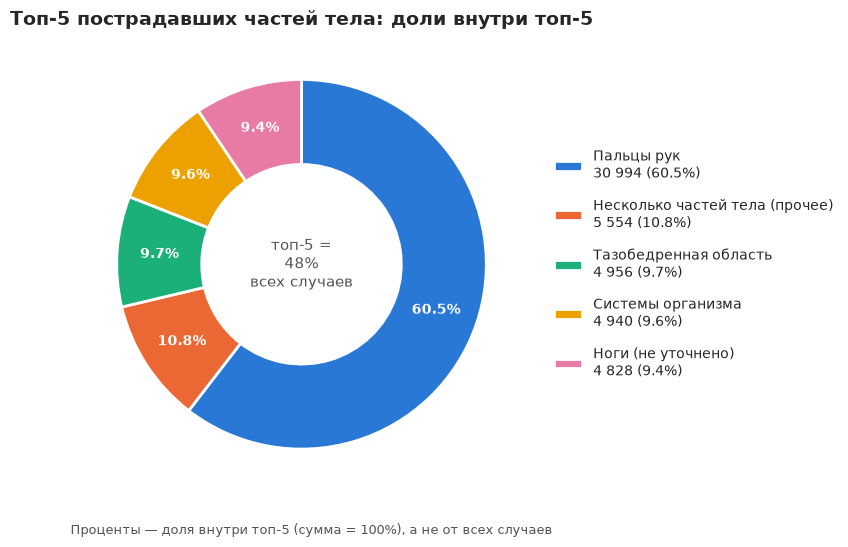

,title_ru,title,cases,pct
1,Пальцы рук,Fingers,30994,29.24
2,Несколько частей тела (прочее),"Multiple body parts, n.e.c.",5554,5.24
3,Тазобедренная область,Hips,4956,4.68
4,Системы организма,Body systems,4940,4.66
5,Ноги (не уточнено),"Leg(s), unspecified",4828,4.55


In [5]:
top_bp = top5("body_part")
for lang in LANGS:
    pie_bar(top_bp, top_bp["title_ru"] if lang == "ru" else top_bp["title"],
            tr("Топ-5 пострадавших частей тела", "Top 5 injured body parts", lang),
            tr("Число случаев", "Number of cases", lang), "09_1_top5_body_parts", lang,
            note=tr("«Пальцы рук» — все коды пальцев вместе; «Не классифицировано» исключено",
                    "“Fingers” — all finger codes combined; “Nonclassifiable” excluded", lang))
for lang in LANGS:
    pie_top5(top_bp, top_bp["title_ru"] if lang == "ru" else top_bp["title"],
             tr("Топ-5 пострадавших частей тела: доли внутри топ-5",
                "Top 5 injured body parts: shares within the top 5", lang),
             "09_1_top5_body_parts_share", lang)
top_bp.round(2)

## 9.2. Топ-5 опасных источников травмы

Основной источник (Source) — объект, непосредственно причинивший травму. Код «Не классифицировано» (2,6% случаев) из рейтинга исключён: это не источник, а отсутствие информации.

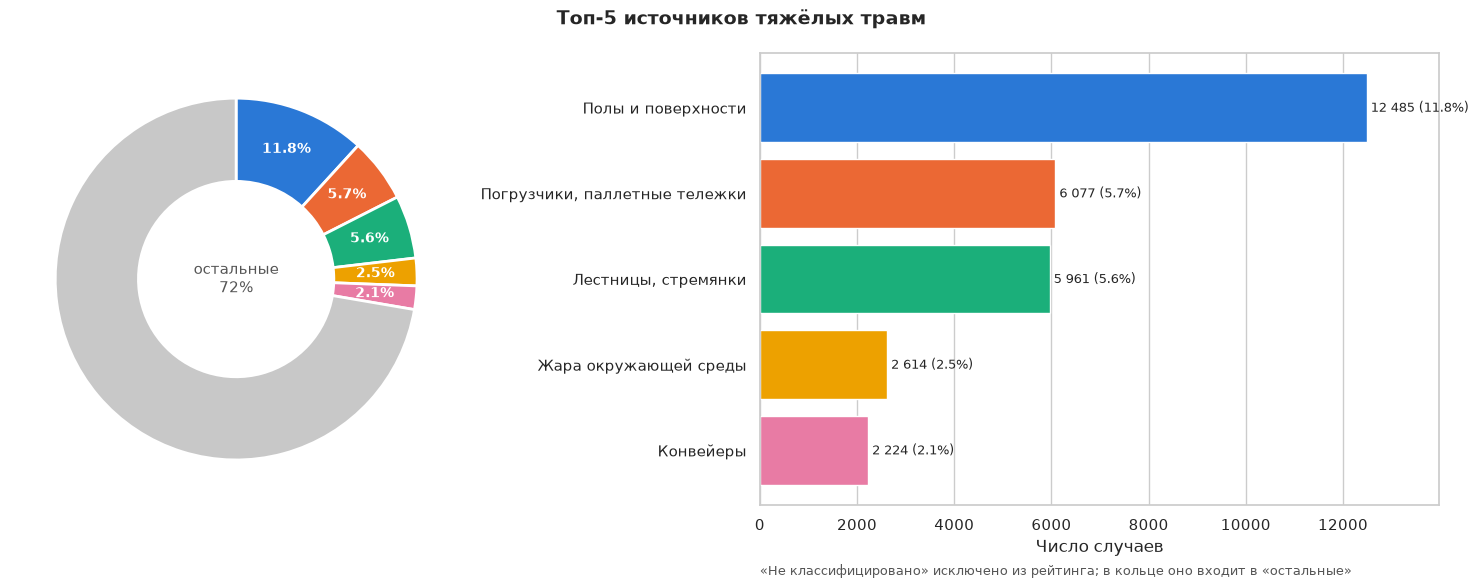

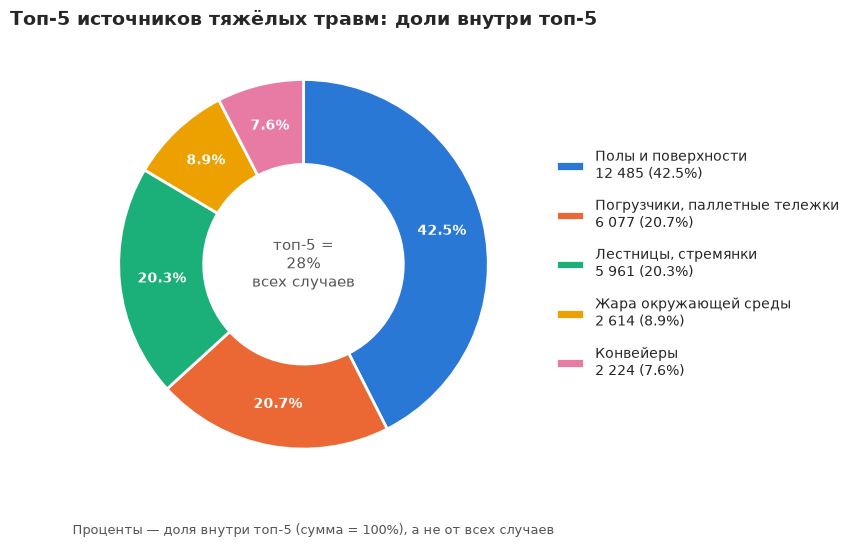

,title_ru,title,cases,pct
1,Полы и поверхности,Floors and walking surfaces,12485,11.78
2,"Погрузчики, паллетные тележки","Forklifts, pallet jacks",6077,5.73
3,"Лестницы, стремянки",Ladders,5961,5.62
4,Жара окружающей среды,Environmental heat,2614,2.47
5,Конвейеры,Conveyors,2224,2.10


In [6]:
top_src = top5("source")
for lang in LANGS:
    pie_bar(top_src, top_src["title_ru"] if lang == "ru" else top_src["title"],
            tr("Топ-5 источников тяжёлых травм", "Top 5 sources of severe injuries", lang),
            tr("Число случаев", "Number of cases", lang), "09_2_top5_sources", lang,
            note=tr("«Не классифицировано» исключено из рейтинга; в кольце оно входит в «остальные»",
                    "“Nonclassifiable” excluded from the ranking; in the ring it is part of “other”", lang))
for lang in LANGS:
    pie_top5(top_src, top_src["title_ru"] if lang == "ru" else top_src["title"],
             tr("Топ-5 источников тяжёлых травм: доли внутри топ-5",
                "Top 5 sources of severe injuries: shares within the top 5", lang),
             "09_2_top5_sources_share", lang)
top_src.round(2)

## 9.3. Топ-5 причин травм (типы происшествий)

Тип происшествия (Event) описывает, как именно человек получил травму. Для каждой причины показана и доля ампутаций.

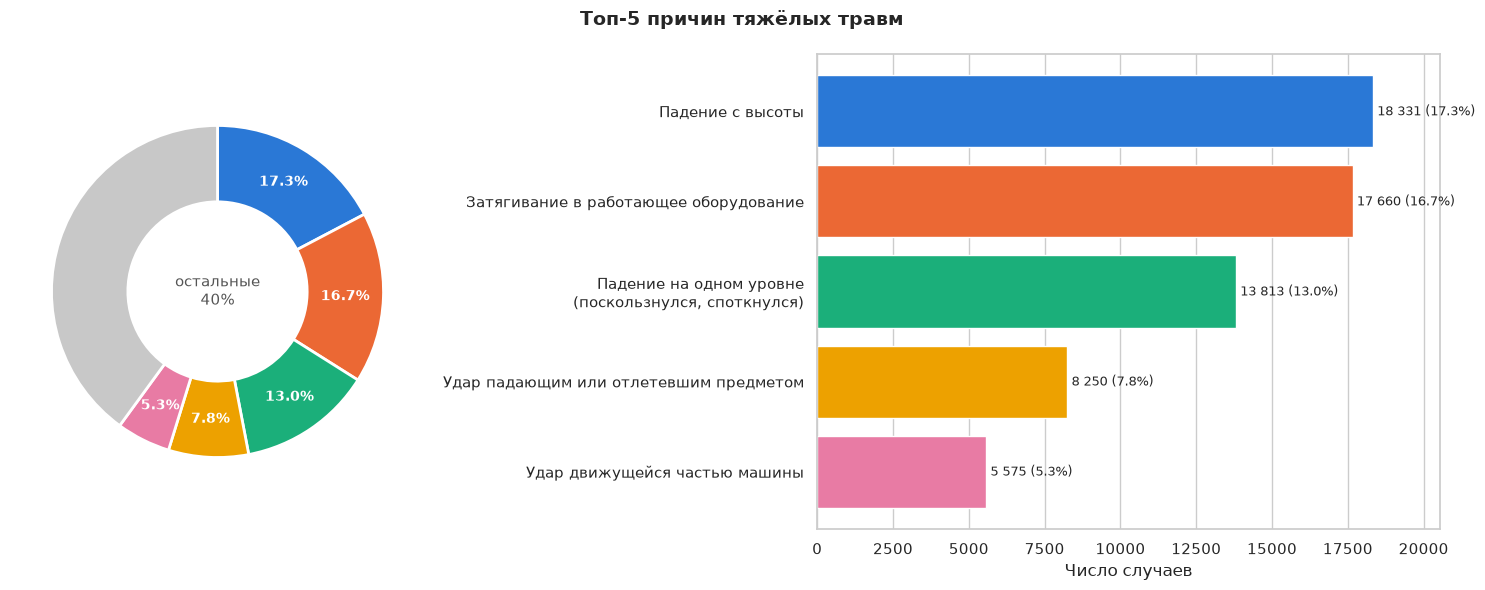

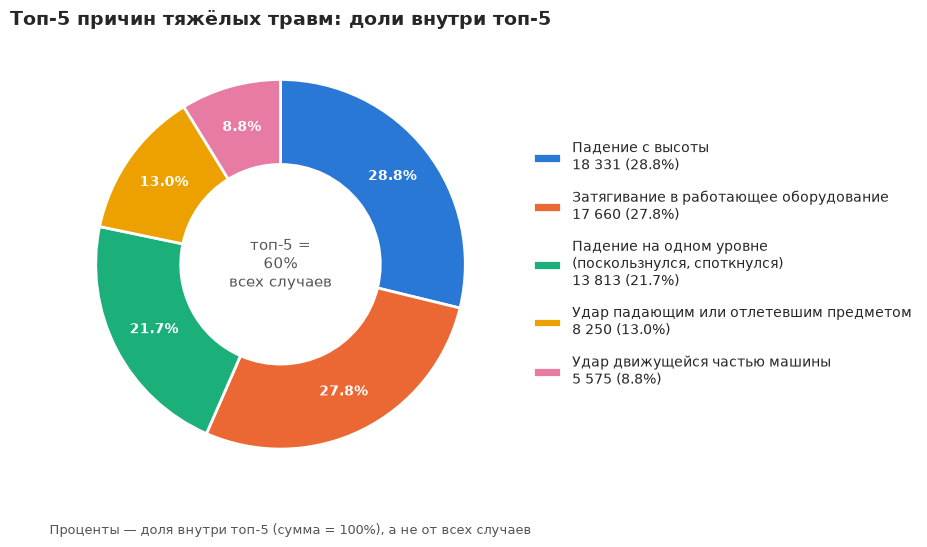

,title_ru,title,cases,pct,pct_amputation
1,Падение с высоты,Fall to lower level,18331,17.29,0.63
2,Затягивание в работающее оборудование,Caught in running equipment,17660,16.66,72.06
3,"Падение на одном уровне (поскользнулся, споткн...","Fall on same level (slip, trip)",13813,13.03,1.66
4,Удар падающим или отлетевшим предметом,Struck by falling or flying object,8250,7.78,16.13
5,Удар движущейся частью машины,Struck by moving machine part,5575,5.26,69.94


In [7]:
top_ev = top5("event")
ev_ru, _ = group_titles("event")
amp = ((cases["severity_code"] & 2) > 0).groupby(ev_ru).mean() * 100
top_ev["pct_amputation"] = top_ev["title_ru"].map(amp)
for lang in LANGS:
    pie_bar(top_ev, top_ev["title_ru"] if lang == "ru" else top_ev["title"],
            tr("Топ-5 причин тяжёлых травм", "Top 5 causes of severe injuries", lang),
            tr("Число случаев", "Number of cases", lang), "09_3_top5_causes", lang)
for lang in LANGS:
    pie_top5(top_ev, top_ev["title_ru"] if lang == "ru" else top_ev["title"],
             tr("Топ-5 причин тяжёлых травм: доли внутри топ-5",
                "Top 5 causes of severe injuries: shares within the top 5", lang),
             "09_3_top5_causes_share", lang)
top_ev.round(2)

## 9.4. Топ-5 отраслей (секторы NAICS)

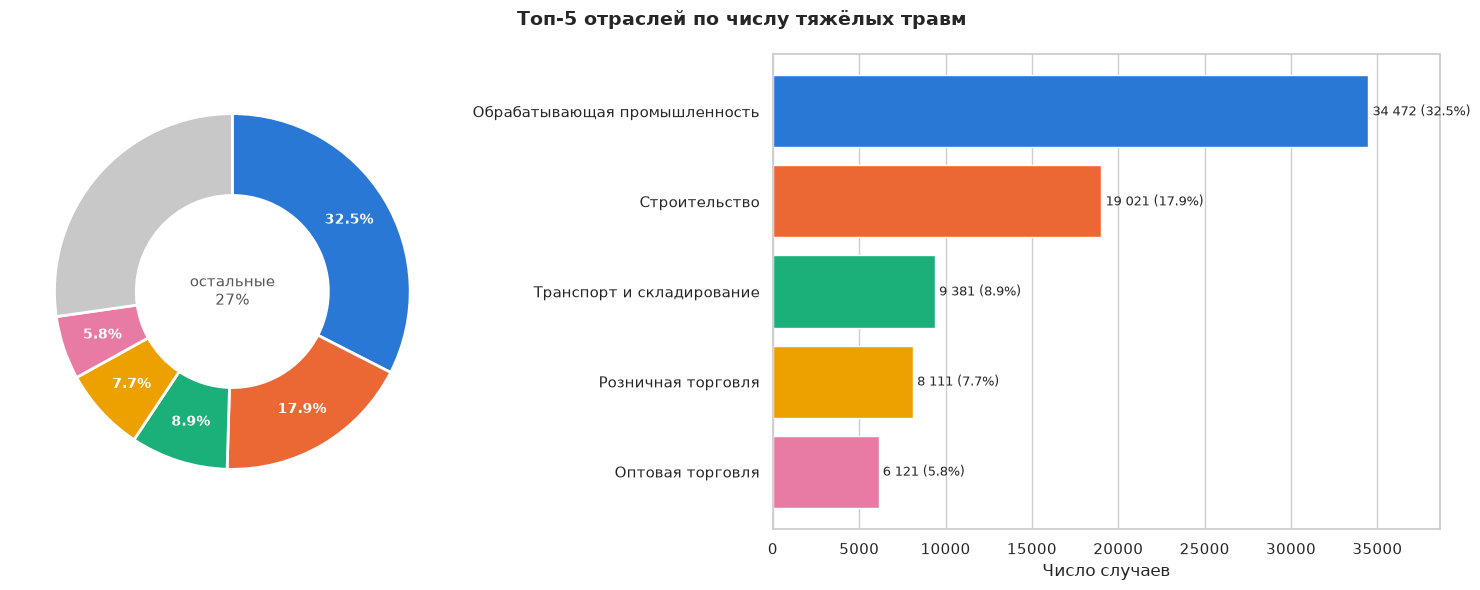

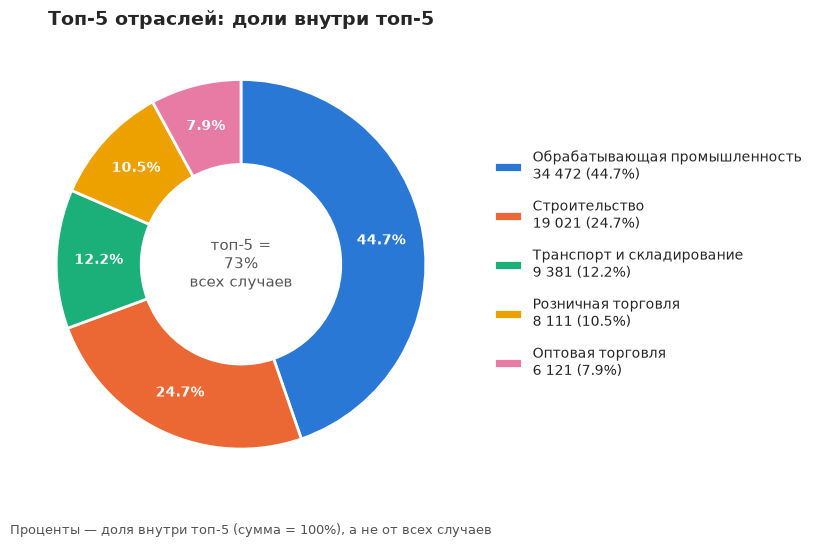

,title_ru,title,cases,pct
sector,,,,
31-33,Обрабатывающая промышленность,Manufacturing,34472,32.52
23,Строительство,Construction,19021,17.95
48-49,Транспорт и складирование,Transportation & warehousing,9381,8.85
44-45,Розничная торговля,Retail trade,8111,7.65
42,Оптовая торговля,Wholesale trade,6121,5.77


In [8]:
sec = cases["sector"].value_counts().rename("cases").to_frame()
sec["pct"] = 100 * sec["cases"] / N
top_sec = sec.head(5).copy()
top_sec["title_ru"] = top_sec.index.map(lambda s: SECTORS[s][0])
top_sec["title"] = top_sec.index.map(lambda s: SECTORS[s][1])

for lang in LANGS:
    pie_bar(top_sec, top_sec["title_ru"] if lang == "ru" else top_sec["title"],
            tr("Топ-5 отраслей по числу тяжёлых травм", "Top 5 industries by severe injuries", lang),
            tr("Число случаев", "Number of cases", lang), "09_4_top5_industries", lang)
for lang in LANGS:
    pie_top5(top_sec, top_sec["title_ru"] if lang == "ru" else top_sec["title"],
             tr("Топ-5 отраслей: доли внутри топ-5",
                "Top 5 industries: shares within the top 5", lang),
             "09_4_top5_industries_share", lang)
top_sec[["title_ru", "title", "cases", "pct"]].round(2)

### Сводная таблица топ-5

In [9]:
summary = pd.DataFrame({
    "Часть тела": [f"{t} ({p:.1f}%)" for t, p in zip(top_bp["title_ru"], top_bp["pct"])],
    "Источник": [f"{t} ({p:.1f}%)" for t, p in zip(top_src["title_ru"], top_src["pct"])],
    "Причина (тип происшествия)": [f"{t} ({p:.1f}%)" for t, p in zip(top_ev["title_ru"], top_ev["pct"])],
    "Отрасль": [f"{t} ({p:.1f}%)" for t, p in zip(top_sec["title_ru"], top_sec["pct"])],
}, index=range(1, 6))
summary.to_csv(TABLES_DIR / "09_top5_summary.csv", encoding="utf-8-sig")
summary

,Часть тела,Источник,Причина (тип происшествия),Отрасль
1,Пальцы рук (29.2%),Полы и поверхности (11.8%),Падение с высоты (17.3%),Обрабатывающая промышленность (32.5%)
2,Несколько частей тела (прочее) (5.2%),"Погрузчики, паллетные тележки (5.7%)",Затягивание в работающее оборудование (16.7%),Строительство (17.9%)
3,Тазобедренная область (4.7%),"Лестницы, стремянки (5.6%)","Падение на одном уровне (поскользнулся, споткн...",Транспорт и складирование (8.9%)
4,Системы организма (4.7%),Жара окружающей среды (2.5%),Удар падающим или отлетевшим предметом (7.8%),Розничная торговля (7.7%)
5,Ноги (не уточнено) (4.6%),Конвейеры (2.1%),Удар движущейся частью машины (5.3%),Оптовая торговля (5.8%)


## 9.5. Где профилактика помогла, а где ещё нужна

Сравниваем среднее число тяжёлых травм **в месяц** в начале периода (**2015–2016**, 24 месяца) и в конце (**2024–2025**, 23 месяца, данные по ноябрь 2025). Два года с каждой стороны сглаживают случайные колебания. Для каждой отрасли — изменение в % и 95% доверительный интервал (отношение частот, приближение Пуассона):

- **снижение значимо** (интервал целиком ниже 0) — профилактика, вероятно, сработала;
- **рост значим** (интервал целиком выше 0) — профилактика нужна в первую очередь;
- интервал пересекает 0 — изменение нельзя отличить от случайности.

**Важно:** это абсолютные числа. Численности работников в базе нет, поэтому снижение может быть связано и с меньшей занятостью в отрасли, и с неполной отчётностью. Для ориентира на графиках показано общее изменение по всем отраслям: отрасль, которая снижается быстрее среднего, улучшается и относительно остальных.

In [10]:
START, END = (2015, 2016), (2024, 2025)
m_start = cases[cases["year"].between(*START)]["event_date"].dt.to_period("M").nunique()
m_end = cases[cases["year"].between(*END)]["event_date"].dt.to_period("M").nunique()

def change_table(key, min_cases=500):
    g = pd.DataFrame({
        "cases_start": cases[cases["year"].between(*START)].groupby(key).size(),
        "cases_end": cases[cases["year"].between(*END)].groupby(key).size(),
        "cases_total": cases.groupby(key).size(),
    }).fillna(0)
    g = g[g["cases_total"] >= min_cases].copy()
    g["per_month_start"] = g["cases_start"] / m_start
    g["per_month_end"] = g["cases_end"] / m_end
    rr = g["per_month_end"] / g["per_month_start"]
    se = np.sqrt(1 / g["cases_start"] + 1 / g["cases_end"])
    g["pct_change"] = 100 * (rr - 1)
    g["ci_low"] = 100 * (rr * np.exp(-1.96 * se) - 1)
    g["ci_high"] = 100 * (rr * np.exp(1.96 * se) - 1)
    g["verdict"] = np.select([g["ci_high"] < 0, g["ci_low"] > 0],
                             ["Снижение — профилактика помогла", "Рост — нужна профилактика"],
                             "Без значимых изменений")
    return g.sort_values("pct_change")

total_change = 100 * ((cases["year"].between(*END).sum() / m_end) / (cases["year"].between(*START).sum() / m_start) - 1)
print(f"Месяцев: {m_start} и {m_end}. Все отрасли вместе: {total_change:+.1f}% случаев в месяц")

sec_ch = change_table("sector")
sec_ch.insert(0, "sector_ru", sec_ch.index.map(lambda s: SECTORS[s][0]))
sec_ch.round(2).to_csv(TABLES_DIR / "09_5_sector_change.csv", encoding="utf-8-sig")
sec_ch[["sector_ru", "cases_start", "cases_end", "per_month_start", "per_month_end",
        "pct_change", "ci_low", "ci_high", "verdict"]].round(1)

Месяцев: 24 и 23. Все отрасли вместе: -7.0% случаев в месяц


,sector_ru,cases_start,cases_end,per_month_start,per_month_end,pct_change,ci_low,ci_high,verdict
sector,,,,,,,,,
51,Информация и связь,219,144.0,9.1,6.3,-31.4,-44.4,-15.3,Снижение — профилактика помогла
21,"Добыча полезных ископаемых, нефти, газа",568,382.0,23.7,16.6,-29.8,-38.4,-20.1,Снижение — профилактика помогла
31-33,Обрабатывающая промышленность,6800,5481.0,283.3,238.3,-15.9,-18.8,-12.8,Снижение — профилактика помогла
11,"Сельское, лесное хозяйство, рыболовство",363,297.0,15.1,12.9,-14.6,-26.8,-0.5,Снижение — профилактика помогла
71,"Искусство, развлечения, отдых",250,222.0,10.4,9.7,-7.3,-22.7,11.0,Без значимых изменений
54,Профессиональные и научно-техн. услуги,339,304.0,14.1,13.2,-6.4,-19.8,9.2,Без значимых изменений
72,Гостиницы и общепит,418,376.0,17.4,16.3,-6.1,-18.3,7.9,Без значимых изменений
48-49,Транспорт и складирование,1716,1550.0,71.5,67.4,-5.7,-12.0,1.0,Без значимых изменений
23,Строительство,3578,3257.0,149.1,141.6,-5.0,-9.4,-0.4,Снижение — профилактика помогла


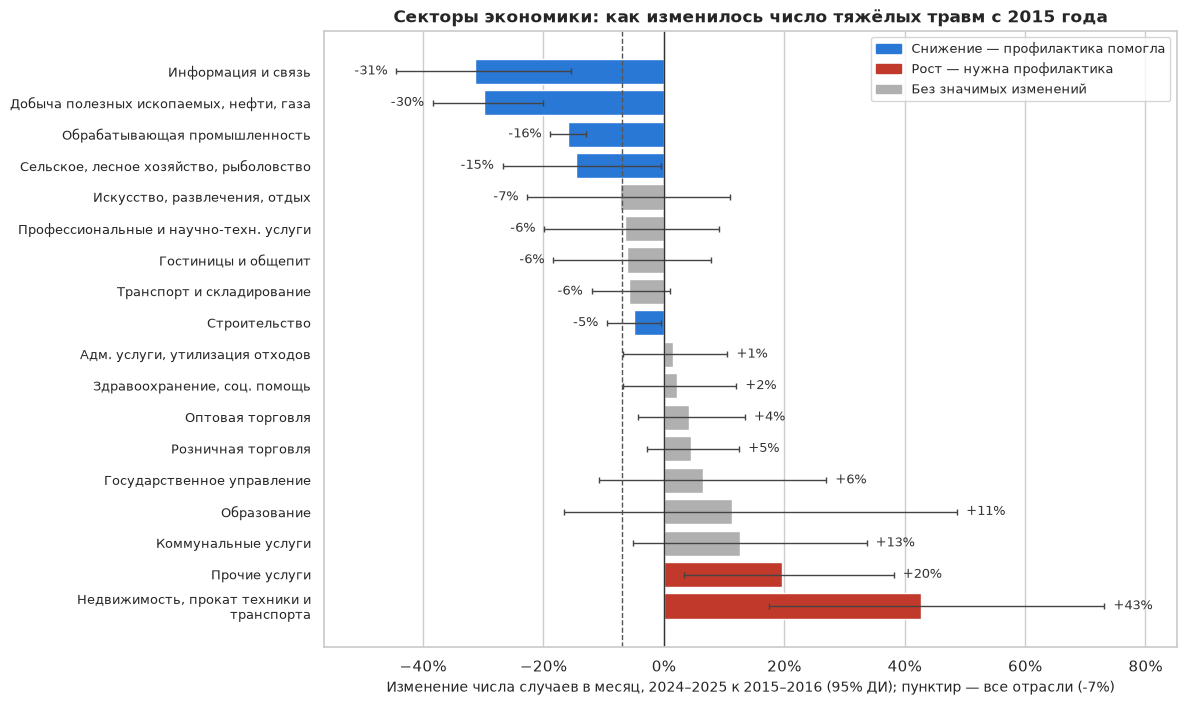

In [11]:
VERDICT_COLORS = {"Снижение — профилактика помогла": SERIES[0],
                  "Рост — нужна профилактика": ACCENT,
                  "Без значимых изменений": "#b0b0b0"}
VERDICT_EN = {"Снижение — профилактика помогла": "Decrease — prevention helped",
              "Рост — нужна профилактика": "Increase — prevention needed",
              "Без значимых изменений": "No significant change"}

def change_chart(g, labels, title, name, lang, height=8):
    fig, ax = plt.subplots(figsize=(11, height))
    y = np.arange(len(g))[::-1]
    colors = g["verdict"].map(VERDICT_COLORS)
    ax.barh(y, g["pct_change"], color=colors,
            xerr=[g["pct_change"] - g["ci_low"], g["ci_high"] - g["pct_change"]],
            capsize=2, error_kw={"lw": 1, "ecolor": "#444444"})
    for yi, v, lo, hi in zip(y, g["pct_change"], g["ci_low"], g["ci_high"]):
        ax.text(hi + 1.5 if v >= 0 else lo - 1.5, yi, f"{v:+.0f}%", ha="left" if v >= 0 else "right",
                va="center", fontsize=9, color="#333333")
    ax.set_xlim(g["ci_low"].min() - 12, g["ci_high"].max() + 12)
    ax.axvline(0, color="#333333", lw=1)
    ax.axvline(total_change, color="#555555", ls="--", lw=1)
    ax.set_yticks(y, [wrap(t, 40) for t in labels], fontsize=9)
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
    ax.set_xlabel(tr(f"Изменение числа случаев в месяц, 2024–2025 к 2015–2016 (95% ДИ); "
                     f"пунктир — все отрасли ({total_change:+.0f}%)",
                     f"Change in cases per month, 2024–2025 vs 2015–2016 (95% CI); "
                     f"dashed — all industries ({total_change:+.0f}%)", lang), fontsize=10)
    present = [v for v in VERDICT_COLORS if (g["verdict"] == v).any()]
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=VERDICT_COLORS[v]) for v in present],
              labels=[v if lang == "ru" else VERDICT_EN[v] for v in present], loc="upper right", fontsize=9)
    finish(fig, name, lang)

for lang in LANGS:
    change_chart(sec_ch, [SECTORS[s][0 if lang == "ru" else 1] for s in sec_ch.index],
                 tr("Секторы экономики: как изменилось число тяжёлых травм с 2015 года",
                    "Economic sectors: change in severe injuries since 2015", lang),
                 "09_5_sector_change", lang)

### Топ-5 отраслей по годам

Индекс: среднее число случаев в месяц в 2015–2016 годах = 100. Линия ниже 100 — травм стало меньше.

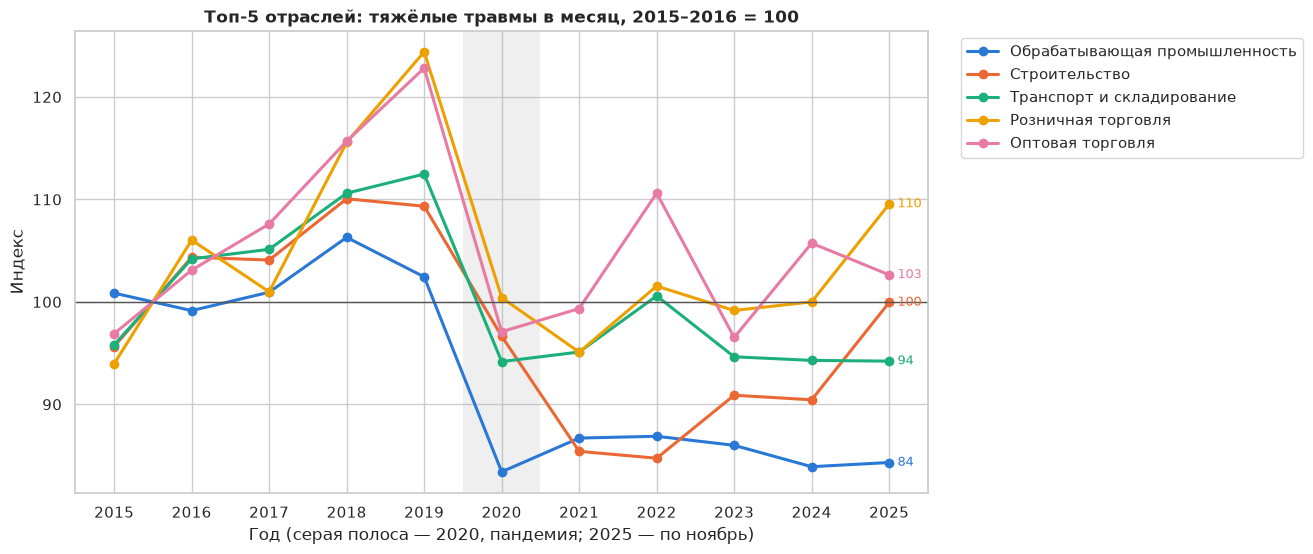

,Обрабатывающая промышленность,Строительство,Транспорт и складирование,Розничная торговля,Оптовая торговля
year,,,,,
2015,101.0,96.0,96.0,94.0,97.0
2016,99.0,104.0,104.0,106.0,103.0
2017,101.0,104.0,105.0,101.0,108.0
2018,106.0,110.0,111.0,116.0,116.0
2019,102.0,109.0,112.0,124.0,123.0
2020,83.0,97.0,94.0,100.0,97.0
2021,87.0,85.0,95.0,95.0,99.0
2022,87.0,85.0,101.0,102.0,111.0
2023,86.0,91.0,95.0,99.0,97.0


In [12]:
months = cases.groupby("year")["event_date"].apply(lambda s: s.dt.to_period("M").nunique())
per_month = pd.crosstab(cases["year"], cases["sector"])[top_sec.index].div(months, axis=0)
index = 100 * per_month / per_month.loc[list(range(START[0], START[1] + 1))].mean()
index.round(1).to_csv(TABLES_DIR / "09_5_top5_sectors_index.csv", encoding="utf-8-sig")

for lang in LANGS:
    k = 0 if lang == "ru" else 1
    fig, ax = plt.subplots(figsize=(11, 6))
    for s, color in zip(top_sec.index, SERIES):
        ax.plot(index.index, index[s], marker="o", color=color, lw=2.2, label=SECTORS[s][k])
        ax.annotate(f"{index[s].iloc[-1]:.0f}", (index.index[-1], index[s].iloc[-1]),
                    xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=color)
    ax.axhline(100, color="#555555", lw=1)
    ax.axvspan(2019.5, 2020.5, color="#b0b0b0", alpha=0.2, lw=0)
    ax.set_title(tr("Топ-5 отраслей: тяжёлые травмы в месяц, 2015–2016 = 100",
                    "Top 5 industries: severe injuries per month, 2015–2016 = 100", lang))
    ax.set_xlabel(tr("Год (серая полоса — 2020, пандемия; 2025 — по ноябрь)",
                     "Year (grey band — 2020, pandemic; 2025 — through November)", lang))
    ax.set_ylabel(tr("Индекс", "Index", lang))
    ax.set_xticks(index.index)
    ax.legend(loc="upper left", bbox_to_anchor=(1.03, 1))
    finish(fig, "09_5_top5_sectors_index", lang)
index.set_axis([SECTORS[s][0] for s in top_sec.index], axis=1).round(0)

### Подсекторы: где снижение сильнее всего и где рост

Подсекторы (3 цифры NAICS) с числом случаев ≥ 500 за весь период: 10 с наибольшим снижением и 10 с наибольшим ростом.

verdict
Без значимых изменений             26
Снижение — профилактика помогла    15
Рост — нужна профилактика           5


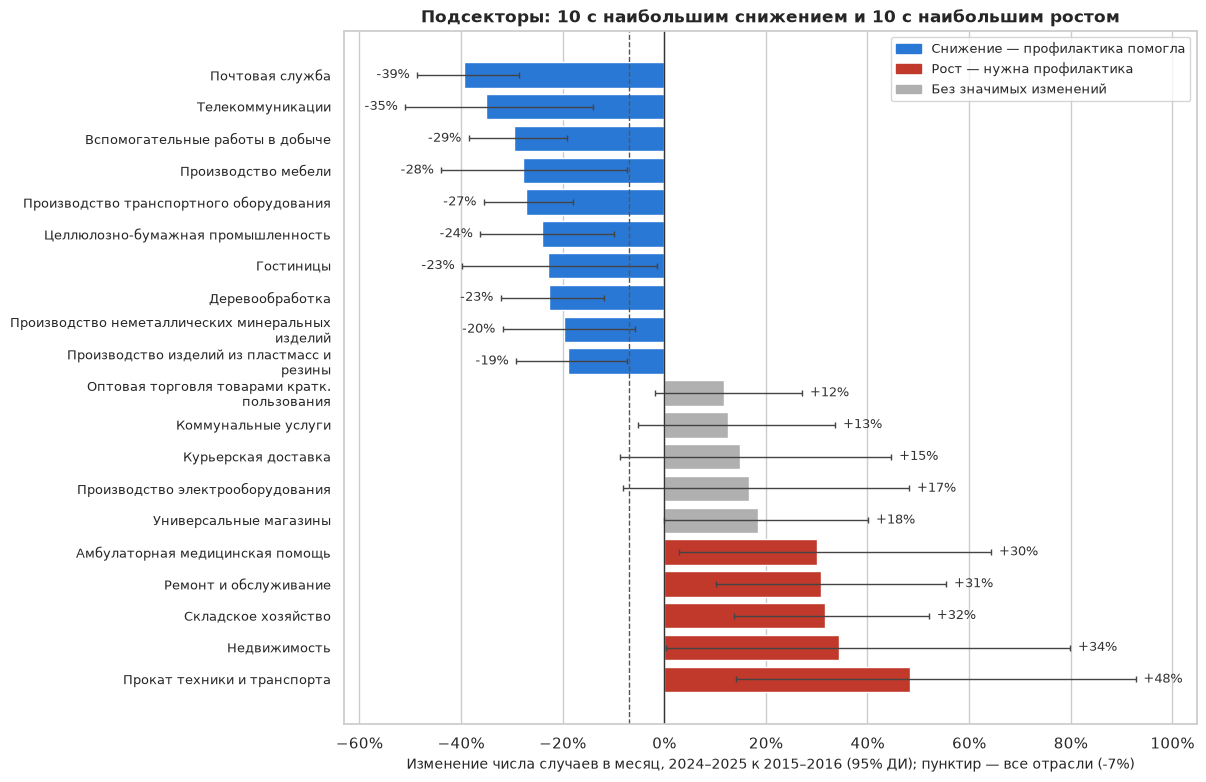

,title_ru,sector_ru,cases_start,cases_end,pct_change,ci_low,ci_high,verdict
subsector,,,,,,,,
491,Почтовая служба,Транспорт и складирование,386.0,224.0,-39.4,-48.6,-28.6,Снижение — профилактика помогла
517,Телекоммуникации,Информация и связь,127.0,79.0,-35.1,-51.0,-14.0,Снижение — профилактика помогла
213,Вспомогательные работы в добыче,"Добыча полезных ископаемых, нефти, газа",509.0,344.0,-29.5,-38.5,-19.1,Снижение — профилактика помогла
337,Производство мебели,Обрабатывающая промышленность,149.0,103.0,-27.9,-43.9,-7.3,Снижение — профилактика помогла
336,Производство транспортного оборудования,Обрабатывающая промышленность,641.0,447.0,-27.2,-35.5,-17.9,Снижение — профилактика помогла
322,Целлюлозно-бумажная промышленность,Обрабатывающая промышленность,304.0,221.0,-24.1,-36.2,-9.8,Снижение — профилактика помогла
721,Гостиницы,Гостиницы и общепит,149.0,110.0,-23.0,-39.8,-1.4,Снижение — профилактика помогла
321,Деревообработка,Обрабатывающая промышленность,525.0,389.0,-22.7,-32.2,-11.9,Снижение — профилактика помогла
327,Производство неметаллических минеральных изделий,Обрабатывающая промышленность,337.0,259.0,-19.8,-31.8,-5.7,Снижение — профилактика помогла


In [13]:
sub_ch = change_table("subsector")
sub_ch["title"] = [naics.get(c) if isinstance(naics.get(c), str) else NAICS_LEGACY_EN.get(c, c) for c in sub_ch.index]
sub_ch["title_ru"] = [naics_ru(c, t) for c, t in zip(sub_ch.index, sub_ch["title"])]
sub_ch["sector_ru"] = sub_ch.index.map(lambda c: SECTORS[sector_code(c)][0])
sub_ch.round(2).to_csv(TABLES_DIR / "09_5_subsector_change.csv", encoding="utf-8-sig")
print(sub_ch["verdict"].value_counts().to_string())

extremes = pd.concat([sub_ch.head(10), sub_ch.tail(10)])
for lang in LANGS:
    change_chart(extremes, extremes["title_ru"] if lang == "ru" else extremes["title"],
                 tr("Подсекторы: 10 с наибольшим снижением и 10 с наибольшим ростом",
                    "Subsectors: 10 largest decreases and 10 largest increases", lang),
                 "09_5_subsector_change", lang, height=9)
extremes[["title_ru", "sector_ru", "cases_start", "cases_end", "pct_change", "ci_low", "ci_high", "verdict"]].round(1)

### Итог: где профилактика помогла, а где ещё нужна

In [14]:
helped = sub_ch[sub_ch["verdict"].str.startswith("Снижение")].sort_values("pct_change")
needed = sub_ch[sub_ch["verdict"].str.startswith("Рост")].sort_values("pct_change", ascending=False)
print("Профилактика помогла (значимое снижение):")
for c, r in helped.iterrows():
    print(f"  {r['title_ru']:<48} {r['pct_change']:+.0f}%")
print("\nНужна профилактика (значимый рост):")
for c, r in needed.iterrows():
    print(f"  {r['title_ru']:<48} {r['pct_change']:+.0f}%")

Профилактика помогла (значимое снижение):
  Почтовая служба                                  -39%
  Телекоммуникации                                 -35%
  Вспомогательные работы в добыче                  -29%
  Производство мебели                              -28%
  Производство транспортного оборудования          -27%
  Целлюлозно-бумажная промышленность               -24%
  Гостиницы                                        -23%
  Деревообработка                                  -23%
  Производство неметаллических минеральных изделий -20%
  Производство изделий из пластмасс и резины       -19%
  Химическая промышленность                        -19%
  Строительство зданий                             -18%
  Металлургия                                      -15%
  Производство металлоизделий                      -12%
  Пищевая промышленность                           -10%

Нужна профилактика (значимый рост):
  Прокат техники и транспорта                      +48%
  Недвижимость           

## Выводы

**Топ-5 в цифрах**

1. **Части тела:** пальцы рук — 29,2% всех тяжёлых травм (почти каждая третья), далее несколько частей тела (5,2%), тазобедренная область (4,7%), системы организма (4,7%, в основном тепловой удар) и ноги (4,6%).
2. **Источники:** полы и поверхности (11,8%), погрузчики и паллетные тележки (5,7%), лестницы и стремянки (5,6%), жара окружающей среды (2,5%), конвейеры (2,1%).
3. **Причины:** падение с высоты (17,3%), затягивание в работающее оборудование (16,7%, из них 72% — ампутации), падение на одном уровне (13,0%), удар падающим или отлетевшим предметом (7,8%), удар движущейся частью машины (5,3%, 70% ампутаций). Эти пять причин дают 60% случаев.
4. **Отрасли:** обрабатывающая промышленность (32,5%), строительство (18,0%), транспорт и склады (8,9%), розничная (7,7%) и оптовая (5,8%) торговля — вместе 73%.

**Где профилактика помогла, а где ещё нужна** (2024–2025 к 2015–2016, в среднем в месяц; по всем отраслям −7%)

5. **Значимое снижение:** обрабатывающая промышленность (−16%) — крупнейший сектор, где тяжёлых травм стало заметно меньше; добыча полезных ископаемых (−30%), информация и связь (−31%), сельское хозяйство (−15%), строительство (−5%, на границе значимости). Внутри промышленности снизились почти все подсекторы: транспортное оборудование (−27%), мебель (−28%), деревообработка (−23%), пластмассы (−19%), металлургия (−15%), пищевая промышленность (−10%). Сильнее всего упало число травм в почтовой службе (−39%).
6. **Значимый рост — здесь профилактика нужна в первую очередь:** складское хозяйство (+32%), ремонт и обслуживание (+31%), амбулаторная медицина (+30%), недвижимость (+34%), прокат техники и транспорта (+48%); среди секторов — недвижимость и прокат техники (+43%) и прочие услуги (+20%).
7. **Без улучшения:** транспорт, розничная и оптовая торговля, здравоохранение, административные услуги остались на уровне 2015–2016 годов (изменение от −6% до +5%, незначимо), хотя в среднем по всем отраслям травм стало на 7% меньше. Относительно других отраслей их положение ухудшилось, и вместе с растущими подсекторами (склады, ремонт) это главные направления для профилактики: погрузчики, падения на одном уровне, лестницы.
8. **Оговорка.** Это абсолютные числа без данных о численности работников: часть снижения может объясняться меньшей занятостью (например, в почтовой службе и добыче) или неполной отчётностью, а рост — расширением отрасли (склады и логистика быстро росли в 2015–2025 годах). Вывод «профилактика помогла» нужно подтверждать данными о занятости (например, BLS).